<a href="https://colab.research.google.com/github/a00377571/lsm-reconocimiento-mediapipe/blob/main/lsm_deteccion_video_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Detección de LSM — Google Colab (MediaPipe Tasks API)


El dataset se guarda con estructura EDA: una línea por frame con coordenadas, distancias, ángulos, orientación, posición de muñeca y etiqueta.


## Índice

1. Instalación de dependencias
2. Importación y descarga del modelo MediaPipe Tasks
3. Extracción de características
4. Recolección de datos desde video
5. Exploración y visualización
6. Entrenamiento del modelo
7. Evaluación del modelo
8. Detección en video y descarga de resultado
9. Cómo usar en Colab
10. Recomendaciones


## 1. Instalación de dependencias


In [ ]:
# Ejecutar solo la primera vez
!pip -q install opencv-python mediapipe pandas scikit-learn joblib matplotlib numpy
!pip install -q gdown

import sys
print('Entorno listo. Python:', sys.version)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.5/41.5 MB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 6.0 MB/s eta 0:00:00
Entorno listo. Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


In [16]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import time
import warnings
import urllib.request
import ssl
from collections import deque, Counter

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                               accuracy_score, ConfusionMatrixDisplay)

import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

from IPython.display import display, Image, clear_output
from google.colab import files

warnings.filterwarnings('ignore')
np.random.seed(42)

print('Todas las librerías importadas correctamente.')
print('MediaPipe version:', mp.__version__)


Todas las librerías importadas correctamente.
MediaPipe version: 1.1.1


In [17]:
# -------------------- Descarga del modelo MediaPipe Tasks --------------------

RUTA_MODELO_TASK = 'hand_landmarker.task'

def crear_detector(ruta_modelo=RUTA_MODELO_TASK, num_manos=2):
    """Crea un detector HandLandmarker de MediaPipe Tasks."""

    if os.path.getsize(ruta_modelo) == 0:
        raise RuntimeError(
            f'El archivo {ruta_modelo} está vacío. '
            'Sube manualmente hand_landmarker.task'
        )

    base_options = python.BaseOptions(model_asset_path=ruta_modelo)
    opciones = vision.HandLandmarkerOptions(
        base_options=base_options,
        running_mode=vision.RunningMode.IMAGE,
        num_hands=num_manos,
        min_hand_detection_confidence=0.7,
        min_hand_presence_confidence=0.7,
        min_tracking_confidence=0.7,
    )
    detector = vision.HandLandmarker.create_from_options(opciones)
    print('Detector HandLandmarker creado.')
    return detector


In [18]:
# -------------------- Rutas y configuración --------------------
RUTA_DATOS = 'datos_lsm'
ARCHIVO_DATOS = 'landmarks_lsm.csv'
RUTA_MODELO = 'modelo_lsm.pkl'
RUTA_SCALER = 'scaler_lsm.pkl'
RUTA_ENCODER = 'encoder_lsm.pkl'
RUTA_COLUMNAS = 'columnas_lsm.pkl'

os.makedirs(RUTA_DATOS, exist_ok=True)

# -------------------- Clases de LSM --------------------
ALFABETO_LSM = [
    'A','B','C','D','E','F','G','H','I','J','K','L','M','N','Ñ','O','P','Q',
    'R','S','T','U','V','W','X','Y','Z',
]

PALABRAS_LSM = ['HOLA', 'GRACIAS', 'ADIOS', 'SI', 'NO', 'PORFAVOR', 'PERDON', 'NOMBRE', 'TU', 'YO']

CLASES_LSM = ALFABETO_LSM + PALABRAS_LSM
print(f'Total de clases definidas: {len(CLASES_LSM)}')
print(CLASES_LSM)


Total de clases definidas: 37
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'Ñ', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'HOLA', 'GRACIAS', 'ADIOS', 'SI', 'NO', 'PORFAVOR', 'PERDON', 'NOMBRE', 'TU', 'YO']


## 2. Conceptos clave: MediaPipe Tasks y estructura EDA

### MediaPipe Tasks (versión 1.1.1+)
Usa `HandLandmarker` en lugar de `mp.solutions.hands`. Detecta hasta 2 manos con 21 landmarks cada una.

### Dibujo manual de landmarks
Como `mp.solutions.drawing_utils` no existe, dibujamos los puntos y conexiones manualmente con OpenCV.

### Estructura del dataset (una línea por frame)
| Grupo | Columnas | Ejemplo |
|---|---|---|
| Coordenadas normalizadas | 63 (21 × 3) | `h1_x0, h1_y0, h1_z0, ...` |
| Distancias desde muñeca | 20 | `h1_dist_1, ..., h1_dist_20` |
| Ángulos articulares | 19 | `h1_angle_thumb_mcp, ...` |
| Orientación | 2 | `h1_hand_ori_x, h1_hand_ori_y` |
| Posición muñeca | 3 | `h1_wrist_x, h1_wrist_y, h1_wrist_z` |
| Segunda mano | idem con prefijo `h2_` | `h2_x0, ...` |
| Número de manos | 1 | `num_manos` |
| Etiqueta | 1 | `label` |


In [19]:
# -------------------- Extracción de características --------------------

DEDOS = {
    'thumb':   [1, 2, 3, 4],
    'index':   [5, 6, 7, 8],
    'middle':  [9, 10, 11, 12],
    'ring':    [13, 14, 15, 16],
    'pinky':   [17, 18, 19, 20],
}

BASES_DEDOS = [1, 5, 9, 13, 17]


def angulo_entre(p1, p2, p3):
    """Ángulo en grados en el punto p2 formado por p1-p2-p3."""
    v1 = p1 - p2
    v2 = p3 - p2
    n1 = np.linalg.norm(v1)
    n2 = np.linalg.norm(v2)
    if n1 < 1e-6 or n2 < 1e-6:
        return 0.0
    cos = np.dot(v1, v2) / (n1 * n2)
    cos = np.clip(cos, -1.0, 1.0)
    return float(np.degrees(np.arccos(cos)))


def extraer_features_mano(lista_landmarks, prefijo):
    """Extrae características EDA de una mano dada su lista de landmarks."""
    pts = np.array([[lm.x, lm.y, lm.z] for lm in lista_landmarks], dtype=np.float32)
    wrist = pts[0].copy()

    pts_c = pts - wrist
    dists = np.linalg.norm(pts_c, axis=1)
    escala = dists.max() if dists.max() > 0 else 1.0
    pts_n = pts_c / escala
    coords = pts_n.flatten()  # 63

    dist_wrist = np.linalg.norm(pts - wrist, axis=1)[1:] / escala

    angulos = []
    noms_ang = []
    for nom, idxs in DEDOS.items():
        a1 = angulo_entre(pts[idxs[0]], pts[idxs[1]], pts[idxs[2]])
        a2 = angulo_entre(pts[idxs[1]], pts[idxs[2]], pts[idxs[3]])
        angulos.extend([a1, a2])
        noms_ang.extend([f'{prefijo}angle_{nom}_mcp', f'{prefijo}angle_{nom}_pip'])

    noms_bases = ['thumb', 'index', 'middle', 'ring', 'pinky']
    for i in range(len(BASES_DEDOS) - 1):
        a = angulo_entre(pts[0], pts[BASES_DEDOS[i]], pts[BASES_DEDOS[i+1]])
        angulos.append(a)
        noms_ang.append(f'{prefijo}angle_spread_{noms_bases[i]}_{noms_bases[i+1]}')

    eje = np.mean(pts[BASES_DEDOS], axis=0) - wrist
    eje = eje / (np.linalg.norm(eje) + 1e-6)
    for nom, b in zip(noms_bases, BASES_DEDOS):
        v = pts[b] - wrist
        v = v / (np.linalg.norm(v) + 1e-6)
        cos = np.clip(np.dot(v, eje), -1.0, 1.0)
        ang = float(np.degrees(np.arccos(cos)))
        angulos.append(ang)
        noms_ang.append(f'{prefijo}angle_{nom}_axis')

    angulos = np.array(angulos, dtype=np.float32)

    ori = (pts[12] - wrist)[:2]
    n = np.linalg.norm(ori)
    ori = ori / n if n > 0 else np.array([0.0, 0.0], dtype=np.float32)

    wrist_pos = wrist

    vector = np.concatenate([coords, dist_wrist, angulos, ori, wrist_pos])
    return vector, noms_ang


In [20]:
def construir_nombres_columnas():
    """Devuelve la lista completa de nombres de columnas del dataset EDA."""
    columnas = []
    for prefijo in ['h1_', 'h2_']:
        for i in range(21):
            columnas += [f'{prefijo}x{i}', f'{prefijo}y{i}', f'{prefijo}z{i}']
        for i in range(1, 21):
            columnas.append(f'{prefijo}dist_{i}')
        DEDOS2 = {'thumb':[1,2,3,4], 'index':[5,6,7,8], 'middle':[9,10,11,12], 'ring':[13,14,15,16], 'pinky':[17,18,19,20]}
        noms_bases = ['thumb','index','middle','ring','pinky']
        for nom in DEDOS2:
            columnas += [f'{prefijo}angle_{nom}_mcp', f'{prefijo}angle_{nom}_pip']
        for i in range(4):
            columnas.append(f'{prefijo}angle_spread_{noms_bases[i]}_{noms_bases[i+1]}')
        for nom in noms_bases:
            columnas.append(f'{prefijo}angle_{nom}_axis')
        columnas += [f'{prefijo}hand_ori_x', f'{prefijo}hand_ori_y']
        columnas += [f'{prefijo}wrist_x', f'{prefijo}wrist_y', f'{prefijo}wrist_z']
    columnas += ['num_manos', 'label']
    return columnas

COLUMNAS_EDA = construir_nombres_columnas()
print(f'Total de columnas del dataset EDA: {len(COLUMNAS_EDA)}')
print('Primeras 10:', COLUMNAS_EDA[:10])
print('Últimas 5:', COLUMNAS_EDA[-5:])


Total de columnas del dataset EDA: 216
Primeras 10: ['h1_x0', 'h1_y0', 'h1_z0', 'h1_x1', 'h1_y1', 'h1_z1', 'h1_x2', 'h1_y2', 'h1_z2', 'h1_x3']
Últimas 5: ['h2_wrist_x', 'h2_wrist_y', 'h2_wrist_z', 'num_manos', 'label']


In [6]:
# -------------------- Explicación de columnas del dataset EDA --------------------

def explicar_columnas_columnas(columnas):
    """Imprime una tabla con el significado de cada columna del dataset EDA."""
    filas = []
    for col in columnas:
        if col == 'label':
            grupo = 'Etiqueta'
            desc = 'Nombre del gesto (clase que se quiere predecir)'
        elif col == 'num_manos':
            grupo = 'Conteo'
            desc = 'Número de manos detectadas en el frame (0, 1 o 2)'
        elif col.startswith('h1_') or col.startswith('h2_'):
            mano = 'Mano 1' if col.startswith('h1_') else 'Mano 2'
            resto = col[3:]  # quitar prefijo h1_ o h2_
            if '_'.join(resto.split('_')[:2]) in ['x', 'y', 'z'] or resto.replace('_','').isdigit():
                # Coordenadas: h1_x0, h1_y5, h1_z20
                partes = resto.split('_')
                if len(partes) >= 2 and partes[0] in ('x','y','z') and partes[1].isdigit():
                    grupo = 'Coordenadas normalizadas'
                    desc = f'{mano} - Posición {partes[0]} del landmark {partes[1]} (0-20)'
                else:
                    grupo = 'Otra característica'
                    desc = f'{mano} - {resto}'
            elif resto.startswith('dist_'):
                idx = resto.split('_')[1]
                grupo = 'Distancia desde muñeca'
                desc = f'{mano} - Distancia muñeca a landmark {idx} (1-20)'
            elif resto.startswith('angle_'):
                grupo = 'Ángulo articular'
                desc = f'{mano} - Ángulo: {resto.replace("angle_","")}'
            elif resto.startswith('hand_ori_'):
                eje = resto.split('_')[2]
                grupo = 'Orientación'
                desc = f'{mano} - Orientación en eje {eje}'
            elif resto.startswith('wrist_'):
                eje = resto.split('_')[1]
                grupo = 'Posición muñeca'
                desc = f'{mano} - Posición muñeca en eje {eje}'
            else:
                grupo = 'Otra característica'
                desc = f'{mano} - {resto}'
        else:
            grupo = 'Desconocido'
            desc = col
        filas.append((col, grupo, desc))

    # Mostrar resumen por grupos
    from collections import Counter
    conteo = Counter(g for _, g, _ in filas)
    print('\n=== RESUMEN DE COLUMNAS DEL DATASET EDA ===')
    print(f'Total de columnas: {len(filas)}')
    print('\nPor grupo:')
    for grupo, cant in conteo.most_common():
        print(f'  {grupo}: {cant} columnas')

    # Mostrar detalle de las primeras columnas de cada grupo
    print('\n=== DETALLE (primeras columnas de cada grupo) ===')
    grupos_vistos = set()
    for col, grupo, desc in filas:
        if grupo not in grupos_vistos:
            grupos_vistos.add(grupo)
            print(f'\n--- {grupo} ---')
            print(f'  {col}: {desc}')
            # Mostrar hasta 3 ejemplos por grupo
            count = 1
            for c2, g2, d2 in filas:
                if g2 == grupo and c2 != col:
                    print(f'  {c2}: {d2}')
                    count += 1
                    if count >= 4:
                        break

explicar_columnas_columnas(COLUMNAS_EDA)



=== RESUMEN DE COLUMNAS DEL DATASET EDA ===
Total de columnas: 216

Por grupo:
  Otra característica: 126 columnas
  Distancia desde muñeca: 40 columnas
  Ángulo articular: 38 columnas
  Posición muñeca: 6 columnas
  Orientación: 4 columnas
  Conteo: 1 columnas
  Etiqueta: 1 columnas

=== DETALLE (primeras columnas de cada grupo) ===

--- Otra característica ---
  h1_x0: Mano 1 - x0
  h1_y0: Mano 1 - y0
  h1_z0: Mano 1 - z0
  h1_x1: Mano 1 - x1

--- Distancia desde muñeca ---
  h1_dist_1: Mano 1 - Distancia muñeca a landmark 1 (1-20)
  h1_dist_2: Mano 1 - Distancia muñeca a landmark 2 (1-20)
  h1_dist_3: Mano 1 - Distancia muñeca a landmark 3 (1-20)
  h1_dist_4: Mano 1 - Distancia muñeca a landmark 4 (1-20)

--- Ángulo articular ---
  h1_angle_thumb_mcp: Mano 1 - Ángulo: thumb_mcp
  h1_angle_thumb_pip: Mano 1 - Ángulo: thumb_pip
  h1_angle_index_mcp: Mano 1 - Ángulo: index_mcp
  h1_angle_index_pip: Mano 1 - Ángulo: index_pip

--- Orientación ---
  h1_hand_ori_x: Mano 1 - Orientación e

In [21]:
# -------------------- Vector completo para 1 o 2 manos --------------------

HAND_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3), (3, 4),
    (0, 5), (5, 6), (6, 7), (7, 8),
    (0, 9), (9, 10), (10, 11), (11, 12),
    (0, 13), (13, 14), (14, 15), (15, 16),
    (0, 17), (17, 18), (18, 19), (19, 20),
    (5, 9), (9, 13), (13, 17), (5, 17),
]


def dibujar_mano(frame, landmarks, conexiones, color_punto=(0, 255, 0), color_linea=(255, 0, 0)):
    """Dibuja landmarks y conexiones de una mano sobre el frame."""
    alto, ancho = frame.shape[:2]
    pts = []
    for lm in landmarks:
        x = int(lm.x * ancho)
        y = int(lm.y * alto)
        pts.append((x, y))
        cv2.circle(frame, (x, y), 3, color_punto, -1)
    for inicio, fin in conexiones:
        if inicio < len(pts) and fin < len(pts):
            cv2.line(frame, pts[inicio], pts[fin], color_linea, 2)


def vector_manos(resultado):
    """Devuelve el vector completo de características para hasta 2 manos."""
    if not resultado.hand_landmarks:
        return np.zeros(len(COLUMNAS_EDA) - 2, dtype=np.float32), 0

    manos = resultado.hand_landmarks
    num = min(len(manos), 2)

    partes = []
    for i in range(num):
        prefijo = 'h1_' if i == 0 else 'h2_'
        vec, _ = extraer_features_mano(manos[i], prefijo)
        partes.append(vec)

    if num == 1:
        tam_mano = 63 + 20 + 19 + 2 + 3
        partes.append(np.zeros(tam_mano, dtype=np.float32))

    vector = np.concatenate(partes)
    return vector, num


def vector_a_fila(vector, num_manos, etiqueta):
    """Convierte el vector de características en una fila para el DataFrame."""
    fila = np.concatenate([vector, [float(num_manos)], [etiqueta]])
    return fila


## 3. Recolección de datos desde video (CSV con estructura EDA)

En Colab sube un video con el botón 📁 o con `files.upload()`, luego ejecuta `capturar_datos_video_colab(...)`.

> **Recomendación:** al menos 300-600 frames por clase, variando ángulos, distancias e iluminación.


In [22]:
# Descargar el archivo usando el ID
!gdown 1B_yP56xShHBsWeMiQgjEugvuZ6-kZkal -O hand_landmarker.task

Downloading...
From: https://drive.google.com/uc?id=1B_yP56xShHBsWeMiQgjEugvuZ6-kZkal
To: /content/hand_landmarker.task
100% 7.82M/7.82M [00:00<00:00, 23.5MB/s]


In [23]:
# Verificar
!ls -lh hand_landmarker.task

-rw-r--r-- 1 root root 7.5M Oct 16 20:08 hand_landmarker.task


Saving A.mp4 to A (2).mp4
Detector HandLandmarker creado.
Vista previa de 5 frames capturados:


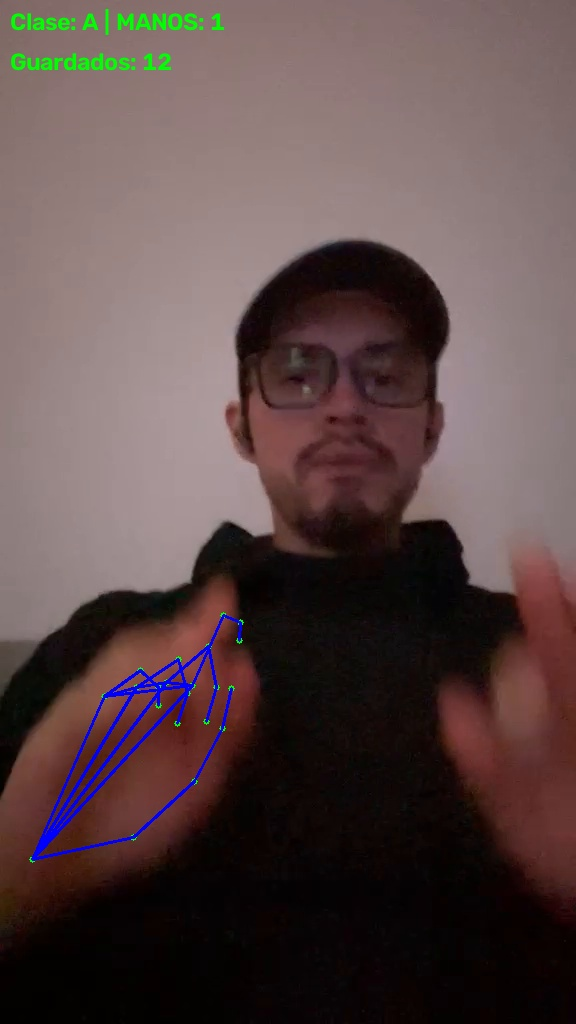

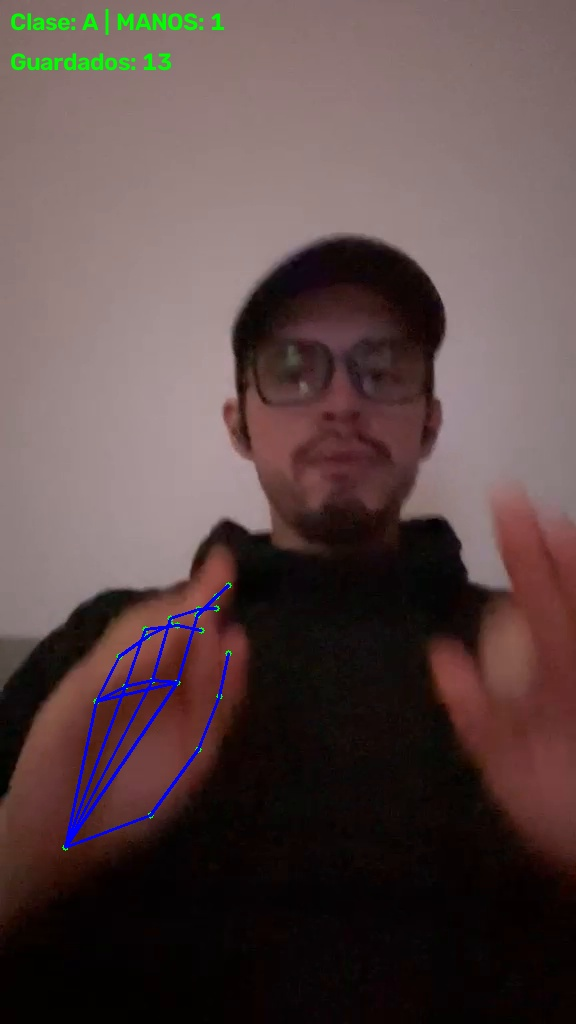

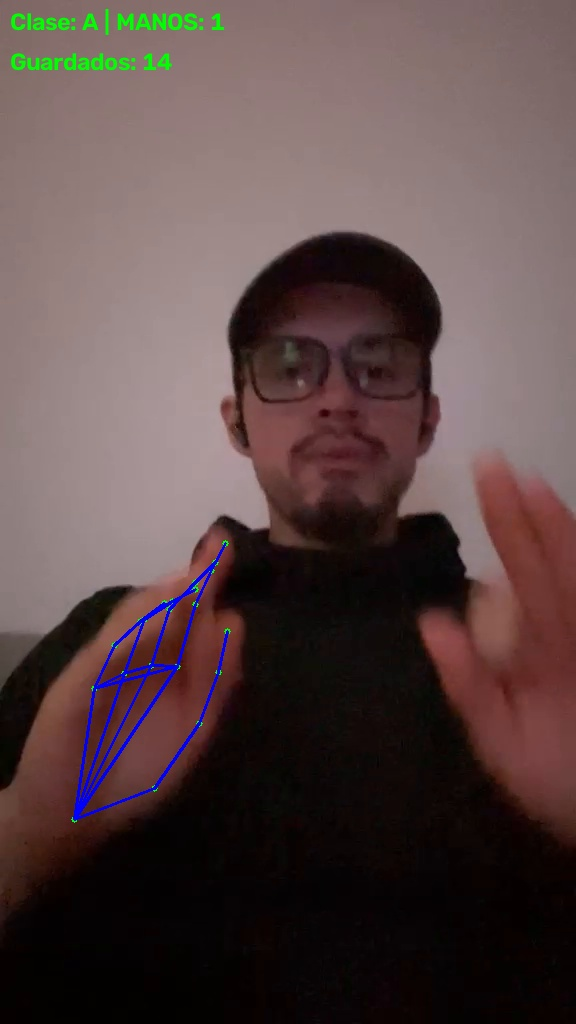

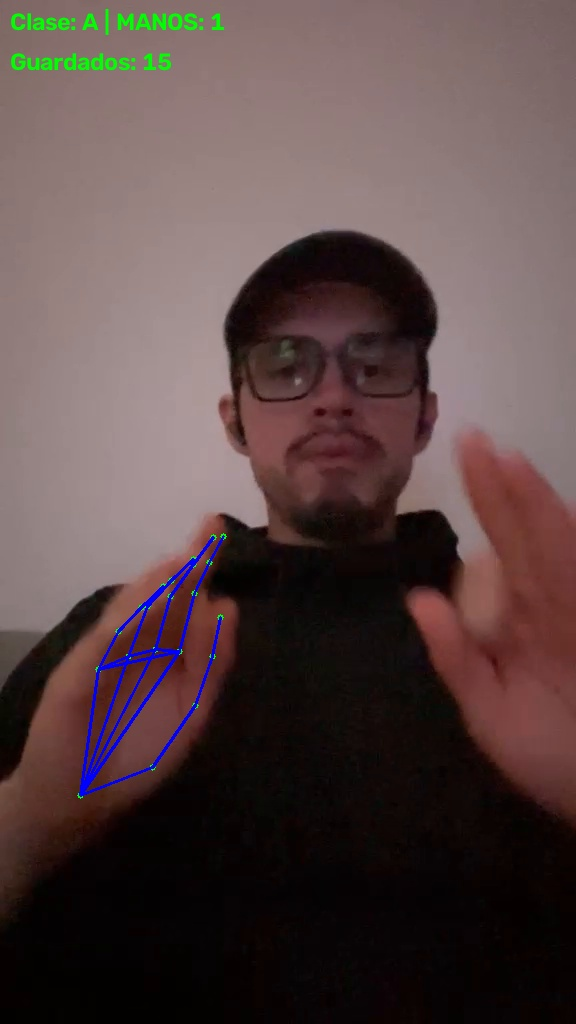

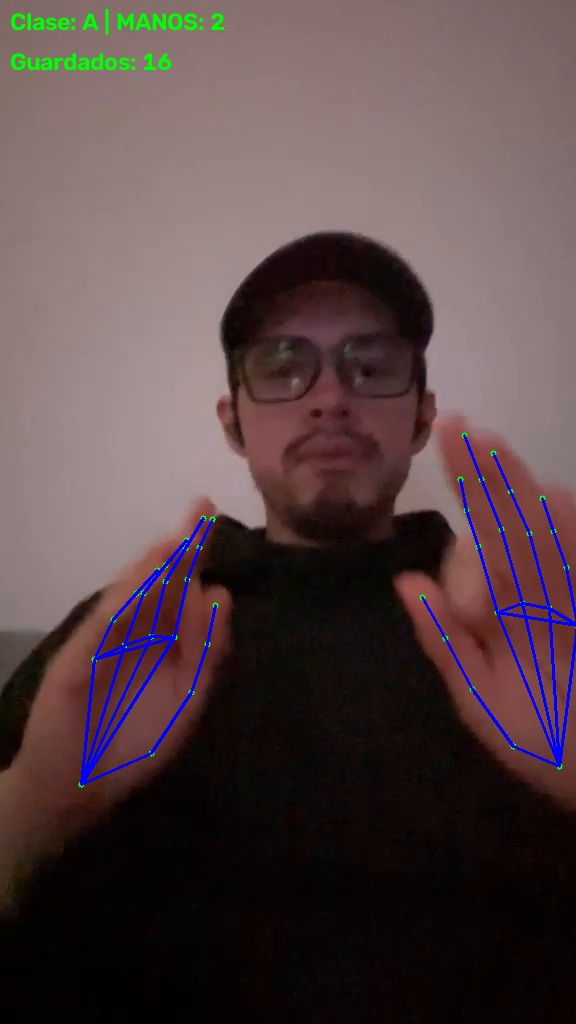

Guardados 93 frames en datos_lsm/A.csv
Columnas: 216


In [24]:
def capturar_datos_video_colab(ruta_video, etiqueta, salida_csv, max_frames=None, cada_n_frames=1, detector=None, mostrar_preview=True, frames_preview=5):
    """Captura características EDA de un video en Colab y las guarda en CSV (una fila por frame)."""
    if detector is None:
        detector = crear_detector()

    cap = cv2.VideoCapture(ruta_video)
    if not cap.isOpened():
        raise RuntimeError(f'No se pudo abrir el video: {ruta_video}')

    filas = []
    frame_idx = 0
    guardados = 0
    preview_frames = []

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        frame_idx += 1
        if frame_idx % cada_n_frames != 0:
            continue

        imagen_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        image_mp = mp.Image(image_format=mp.ImageFormat.SRGB, data=imagen_rgb)
        resultado = detector.detect(image_mp)

        vector, num_manos = vector_manos(resultado)

        frame_dibujo = frame.copy()
        if resultado.hand_landmarks:
            for mano_lms in resultado.hand_landmarks[:2]:
                dibujar_mano(frame_dibujo, mano_lms, HAND_CONNECTIONS)
            estado = f'MANOS: {num_manos}'
        else:
            estado = 'SIN MANOS'

        cv2.putText(frame_dibujo, f'Clase: {etiqueta} | {estado}', (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
        cv2.putText(frame_dibujo, f'Guardados: {guardados}', (10, 70),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)

        if mostrar_preview and len(preview_frames) < frames_preview and resultado.hand_landmarks:
            _, buf = cv2.imencode('.jpg', frame_dibujo)
            preview_frames.append(buf.tobytes())

        fila = vector_a_fila(vector, num_manos, etiqueta)
        filas.append(fila)
        guardados += 1

    cap.release()

    if mostrar_preview and preview_frames:
        print(f'Vista previa de {len(preview_frames)} frames capturados:')
        for img_bytes in preview_frames:
            display(Image(data=img_bytes, format='jpeg'))

    df = pd.DataFrame(filas, columns=COLUMNAS_EDA)
    df.to_csv(salida_csv, index=False)
    print(f'Guardados {guardados} frames en {salida_csv}')
    print(f'Columnas: {len(COLUMNAS_EDA)}')
    return df

# Ejemplo en Colab:
subido = files.upload()  # sube tu video, ej: 'A.mp4'
det = crear_detector()
df_a = capturar_datos_video_colab('A.mp4', 'A', 'datos_lsm/A.csv', detector=det, max_frames=400, cada_n_frames=1)


In [25]:
def unir_datos(carpeta=RUTA_DATOS, salida=ARCHIVO_DATOS):
    """Une todos los CSV de la carpeta en un solo DataFrame con estructura EDA."""
    archivos = [f for f in os.listdir(carpeta) if f.endswith('.csv')]
    if not archivos:
        raise FileNotFoundError(f'No se encontraron CSV en {carpeta}')

    partes = []
    for archivo in archivos:
        ruta = os.path.join(carpeta, archivo)
        df_parcial = pd.read_csv(ruta)
        faltantes = [c for c in COLUMNAS_EDA if c not in df_parcial.columns]
        for c in faltantes:
            df_parcial[c] = 0.0
        df_parcial = df_parcial[COLUMNAS_EDA]
        partes.append(df_parcial)
        print(f'{archivo}: {len(df_parcial)} frames, clases: {sorted(df_parcial["label"].unique().tolist())}')

    df = pd.concat(partes, ignore_index=True)
    df.to_csv(salida, index=False)
    print(f'\nTotal unido: {len(df)} frames en {salida}')
    print('Distribución de clases:')
    print(df['label'].value_counts().sort_index())
    return df

# Ejecutar solo si ya tienes datos recolectados:
df_total = unir_datos()


A.csv: 93 frames, clases: ['A']

Total unido: 93 frames en landmarks_lsm.csv
Distribución de clases:
label
A    93
Name: count, dtype: int64


## 4. Exploración y visualización de los datos


Datos cargados: 93 frames

Clases y conteo:
label
A    93
Name: count, dtype: int64


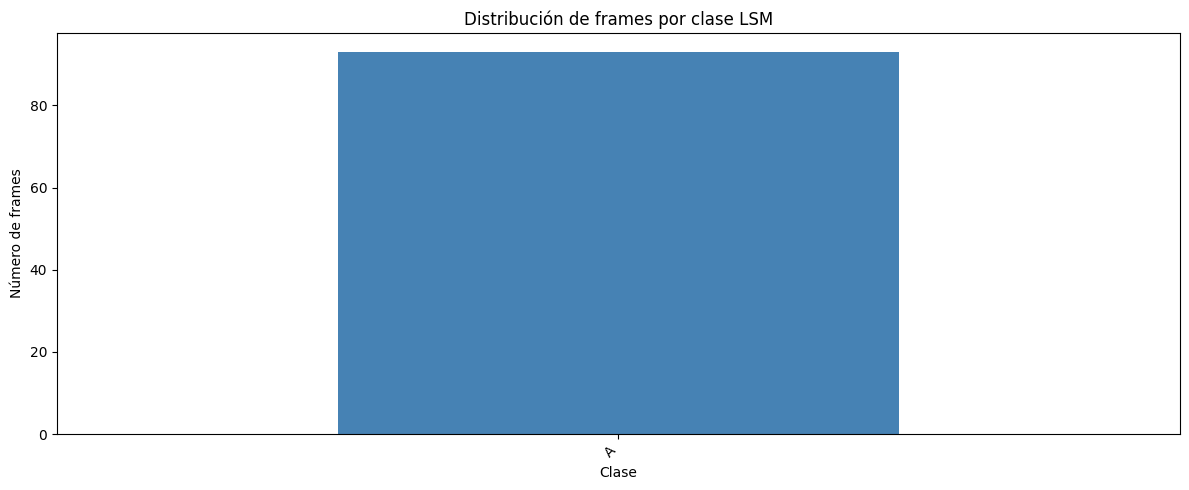

In [26]:
# Cargar datos (genera un dataset de ejemplo si no existe el CSV)
if not os.path.exists(ARCHIVO_DATOS) or os.path.getsize(ARCHIVO_DATOS) == 0:
    print('No hay datos reales. Generando dataset sintético de ejemplo...')
    np.random.seed(42)
    filas = []
    for clase in CLASES_LSM[:10]:
        for _ in range(200):
            vector = np.random.normal(loc=0.0, scale=0.3, size=len(COLUMNAS_EDA) - 2)
            filas.append(vector_a_fila(vector, 1, clase))
    df_total = pd.DataFrame(filas, columns=COLUMNAS_EDA)
    df_total.to_csv(ARCHIVO_DATOS, index=False)
    print(f'Dataset de ejemplo creado: {len(df_total)} frames')
else:
    df_total = pd.read_csv(ARCHIVO_DATOS)
    df_total = df_total[COLUMNAS_EDA]
    print(f'Datos cargados: {len(df_total)} frames')

print('\nClases y conteo:')
print(df_total['label'].value_counts().sort_index())

plt.figure(figsize=(12, 5))
df_total['label'].value_counts().sort_index().plot(kind='bar', color='steelblue')
plt.title('Distribución de frames por clase LSM')
plt.xlabel('Clase')
plt.ylabel('Número de frames')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [27]:
feature_cols = [c for c in COLUMNAS_EDA if c not in ('num_manos', 'label')]
X = df_total[feature_cols].values.astype(np.float32)
y = df_total['label'].values

le = LabelEncoder()
y_enc = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.25, stratify=y_enc, random_state=42)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(f'Entrenamiento: {X_train_s.shape} | Prueba: {X_test_s.shape}')
print(f'Clases: {list(le.classes_)}')
print(f'Número de características: {X_train_s.shape[1]}')


Entrenamiento: (69, 214) | Prueba: (24, 214)
Clases: ['A']
Número de características: 214


## 5. Entrenamiento del modelo de clasificación


In [ ]:
modelo_rf = RandomForestClassifier(n_estimators=300, max_depth=None,
                                   min_samples_split=5, min_samples_leaf=2,
                                   class_weight='balanced', random_state=42, n_jobs=-1)

modelo_mlp = MLPClassifier(hidden_layer_sizes=(128, 64), activation='relu',
                           solver='adam', max_iter=500, early_stopping=True,
                           random_state=42)

print('Entrenando Random Forest...')
modelo_rf.fit(X_train_s, y_train)

print('Entrenando MLP...')
modelo_mlp.fit(X_train_s, y_train)

cv_rf = cross_val_score(modelo_rf, X_train_s, y_train, cv=5, n_jobs=-1).mean()
cv_mlp = cross_val_score(modelo_mlp, X_train_s, y_train, cv=5, n_jobs=-1).mean()
print(f'CV Random Forest: {cv_rf:.4f} | CV MLP: {cv_mlp:.4f}')

modelo_final = modelo_rf if cv_rf >= cv_mlp else modelo_mlp
nombre_modelo = 'Random Forest' if modelo_final is modelo_rf else 'MLP'
print(f'Modelo seleccionado: {nombre_modelo}')

joblib.dump(modelo_final, RUTA_MODELO)
joblib.dump(scaler, RUTA_SCALER)
joblib.dump(le, RUTA_ENCODER)
joblib.dump(COLUMNAS_EDA, RUTA_COLUMNAS)
print(f'Modelo guardado en {RUTA_MODELO}')
print(f'Columnas guardadas en {RUTA_COLUMNAS}')


Entrenando Random Forest...
Entrenando MLP...
CV Random Forest: 1.0000 | CV MLP: 1.0000
Modelo seleccionado: Random Forest
Modelo guardado en modelo_lsm.pkl
Columnas guardadas en columnas_lsm.pkl


## 6. Evaluación del modelo


Accuracy en prueba: 1.0000

Informe de clasificación:
              precision    recall  f1-score   support

           A       1.00      1.00      1.00        24

    accuracy                           1.00        24
   macro avg       1.00      1.00      1.00        24
weighted avg       1.00      1.00      1.00        24



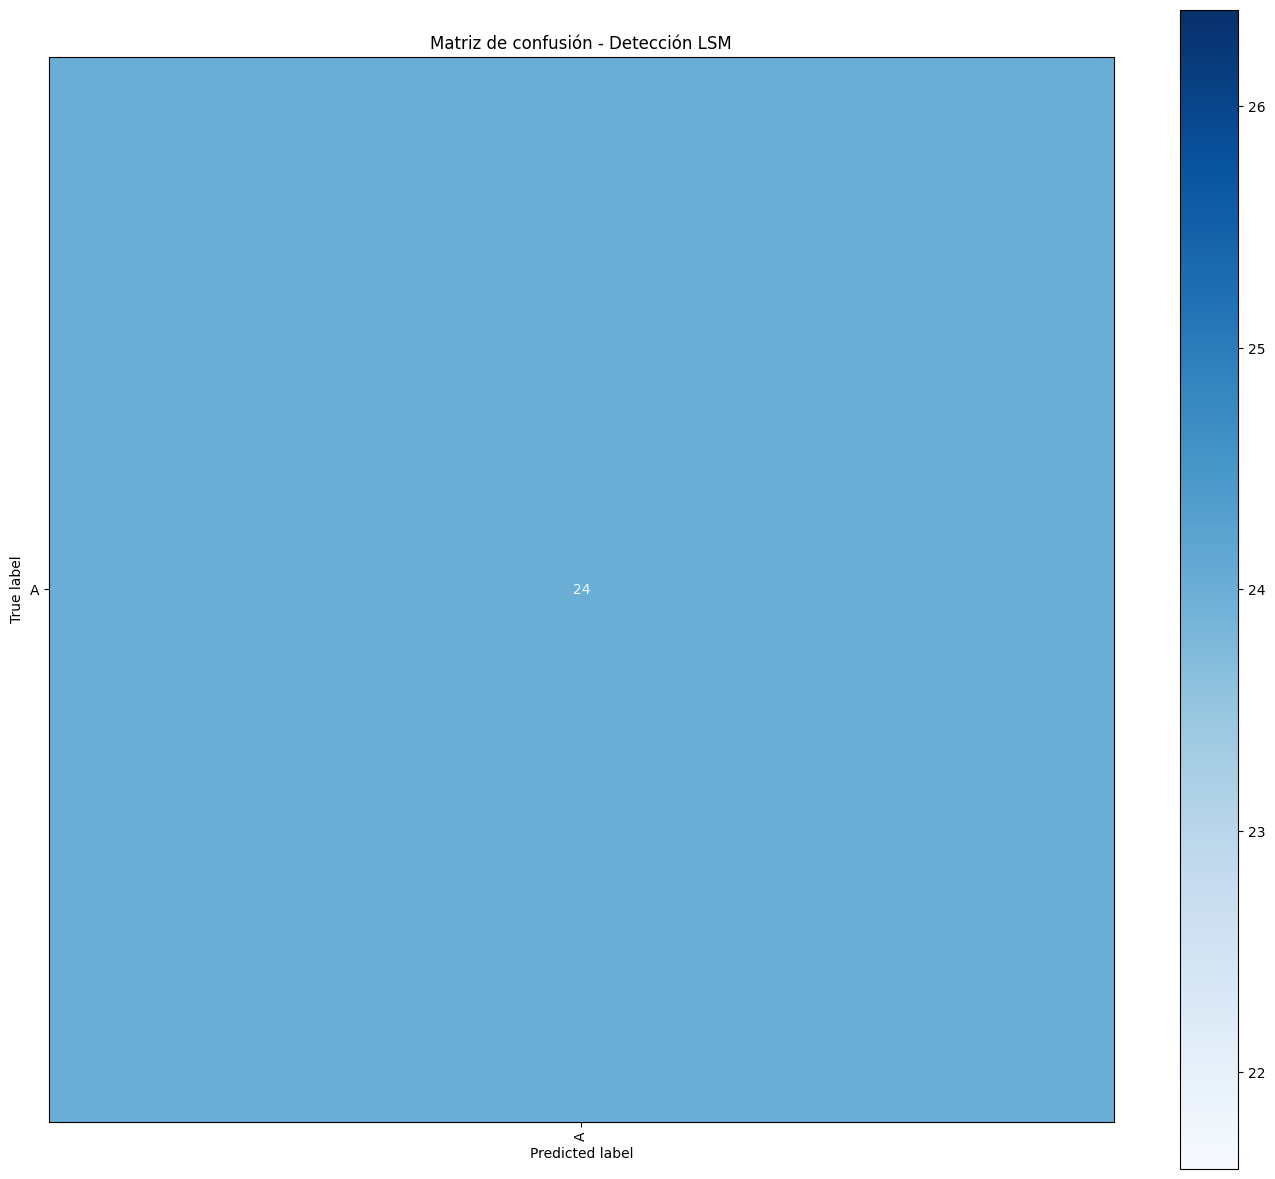

In [ ]:
y_pred = modelo_final.predict(X_test_s)
acc = accuracy_score(y_test, y_pred)
print(f'Accuracy en prueba: {acc:.4f}')
print('\nInforme de clasificación:')
print(classification_report(y_test, y_pred, target_names=[str(c) for c in le.classes_]))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
fig, ax = plt.subplots(figsize=(14, 12))
disp.plot(ax=ax, cmap='Blues', values_format='d')
plt.title('Matriz de confusión - Detección LSM')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


## 7. Detección en video (Colab)

Esta sección procesa un **video subido**, clasifica cada frame y guarda un video de salida con las detecciones. Luego lo descargas automáticamente.

Usa una ventana deslizante con voto mayoritario para evitar parpadeos entre frames.


In [28]:
class DetectorLSM:
    """Detector de LSM con MediaPipe Tasks y suavizado temporal."""

    def __init__(self, ruta_modelo=RUTA_MODELO, ruta_scaler=RUTA_SCALER,
                 ruta_encoder=RUTA_ENCODER, ruta_columnas=RUTA_COLUMNAS,
                 ruta_task=RUTA_MODELO_TASK, ventana=7, umbral_confianza=0.60):
        for p in [ruta_modelo, ruta_scaler, ruta_encoder, ruta_columnas, ruta_task]:
            if not os.path.exists(p):
                raise FileNotFoundError(f'No se encontró {p}. Entrena o descarga primero.')
        self.modelo = joblib.load(ruta_modelo)
        self.scaler = joblib.load(ruta_scaler)
        self.le = joblib.load(ruta_encoder)
        self.columnas = joblib.load(ruta_columnas)
        self.detector = crear_detector(ruta_task, num_manos=2)
        self.ventana = ventana
        self.umbral_confianza = umbral_confianza
        self.historial = deque(maxlen=ventana)
        self.ultima_prediccion = '---'

    def predecir_frame(self, frame):
        imagen_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        image_mp = mp.Image(image_format=mp.ImageFormat.SRGB, data=imagen_rgb)
        resultado = self.detector.detect(image_mp)

        vector, num_manos = vector_manos(resultado)

        if num_manos == 0:
            self.historial.append(None)
            return frame, '---', 0.0, 0

        Xs = self.scaler.transform(vector.reshape(1, -1))

        probs = self.modelo.predict_proba(Xs)[0] if hasattr(self.modelo, 'predict_proba') else None
        pred = self.modelo.predict(Xs)[0]
        etiqueta = self.le.inverse_transform([pred])[0]
        conf = float(np.max(probs)) if probs is not None else 1.0

        self.historial.append(etiqueta if conf >= self.umbral_confianza else None)
        votos = [v for v in self.historial if v is not None]
        if votos:
            etiqueta_final, _ = Counter(votos).most_common(1)[0]
        else:
            etiqueta_final = '---'
        self.ultima_prediccion = etiqueta_final

        if resultado.hand_landmarks:
            for mano_lms in resultado.hand_landmarks[:2]:
                dibujar_mano(frame, mano_lms, HAND_CONNECTIONS)

        return frame, etiqueta_final, conf, num_manos


Saving entrada.mp4 to entrada (2).mp4
Detector HandLandmarker creado.
Procesando video...
Vista previa de 8 frames procesados:


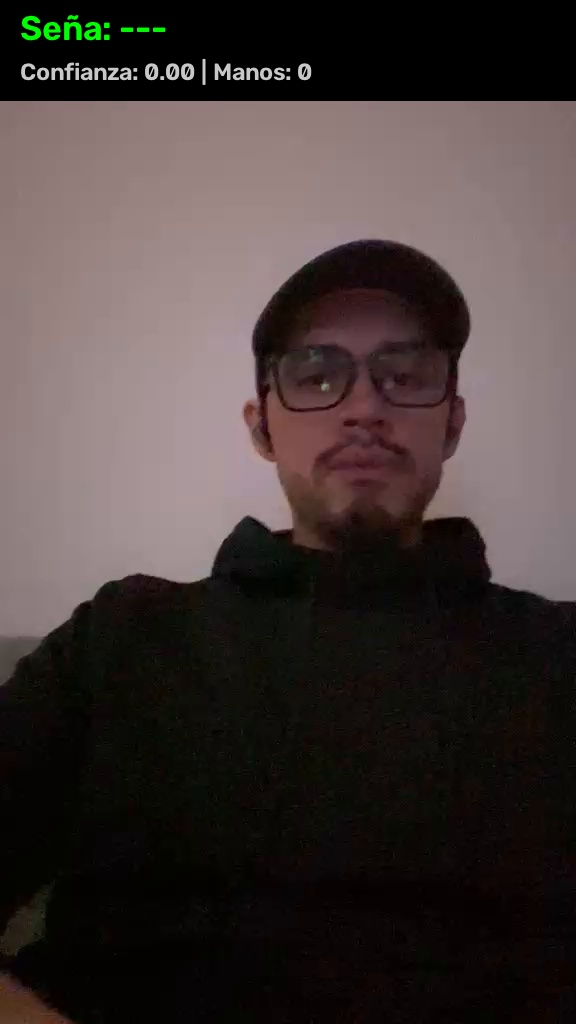

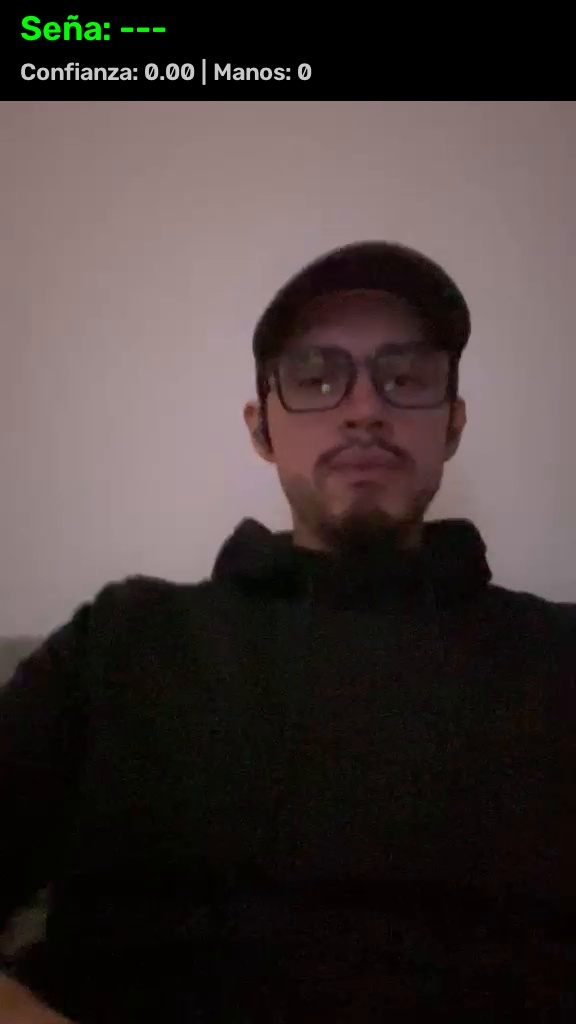

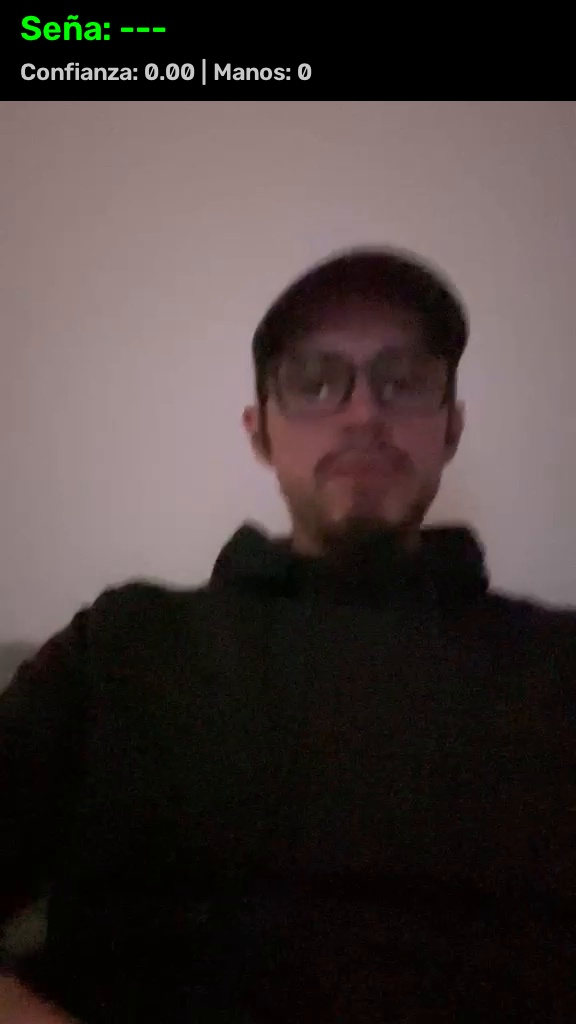

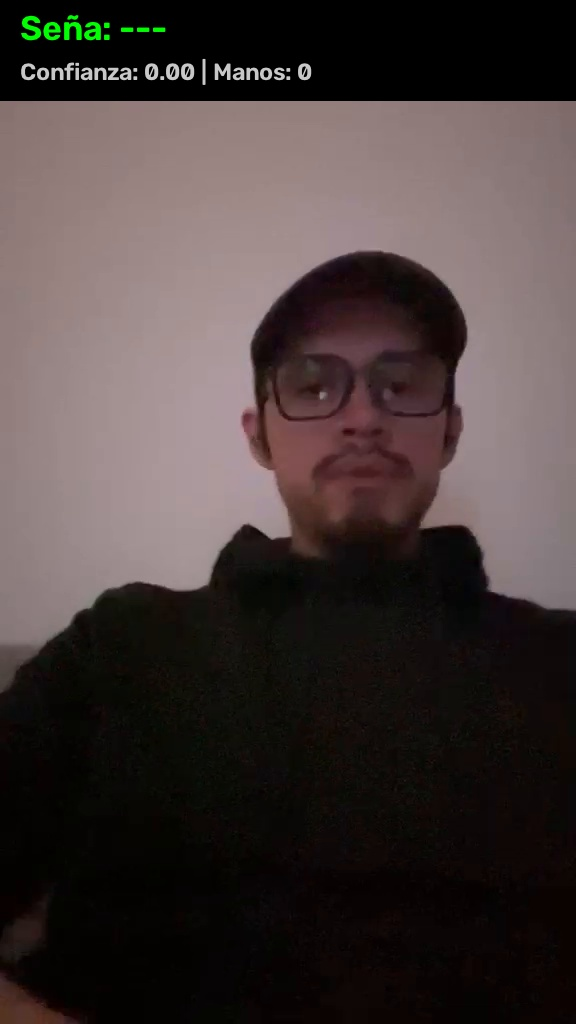

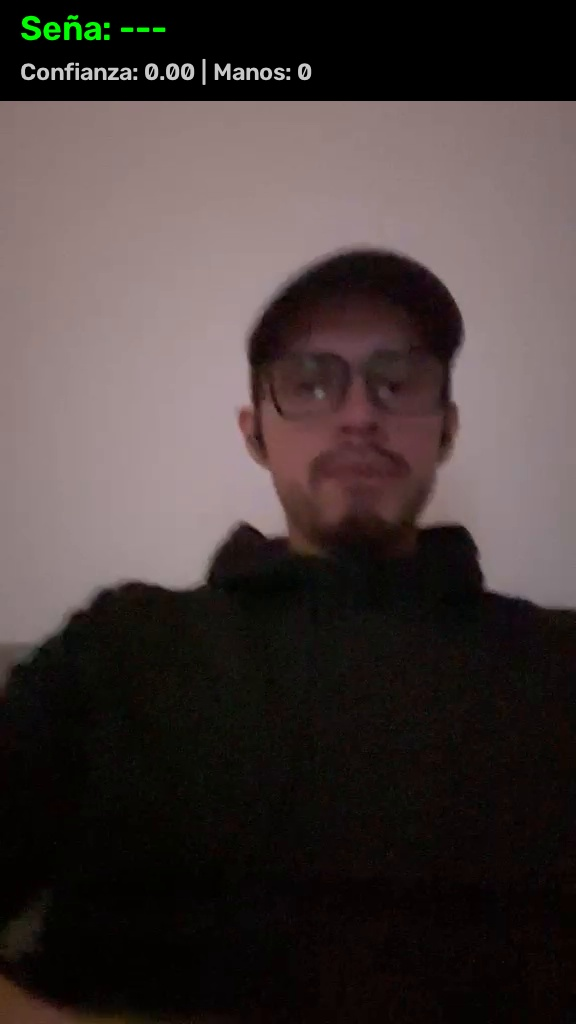

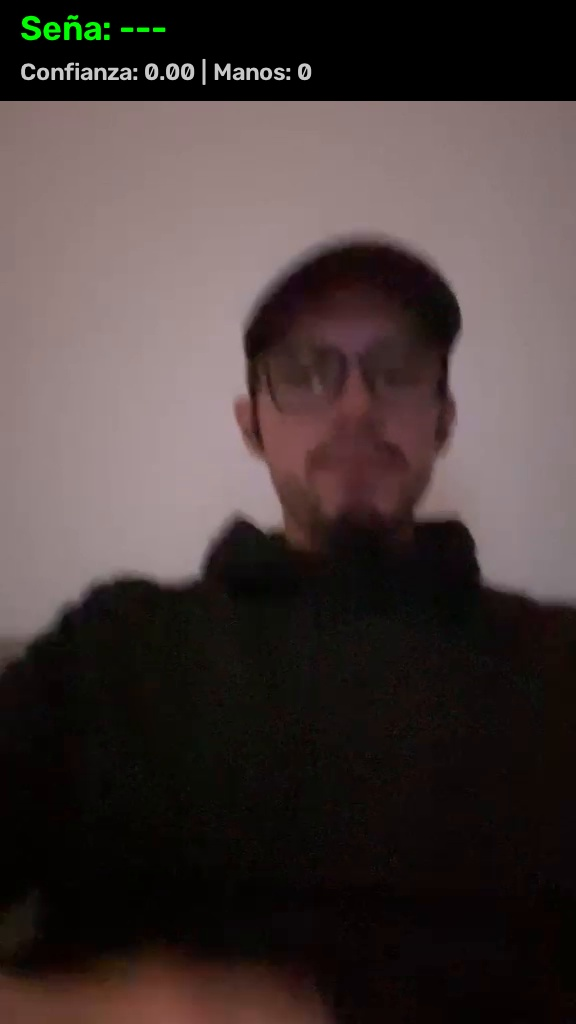

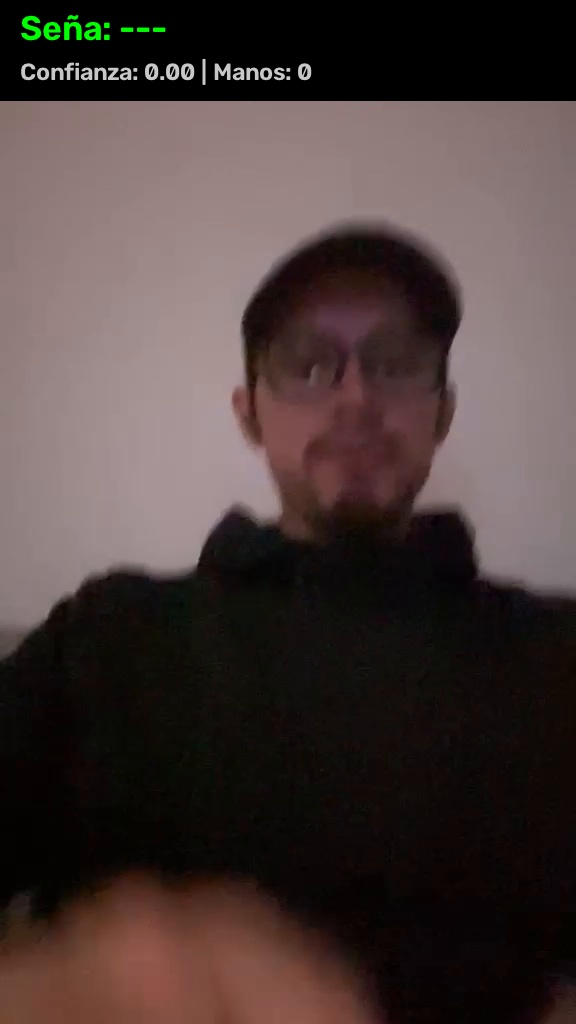

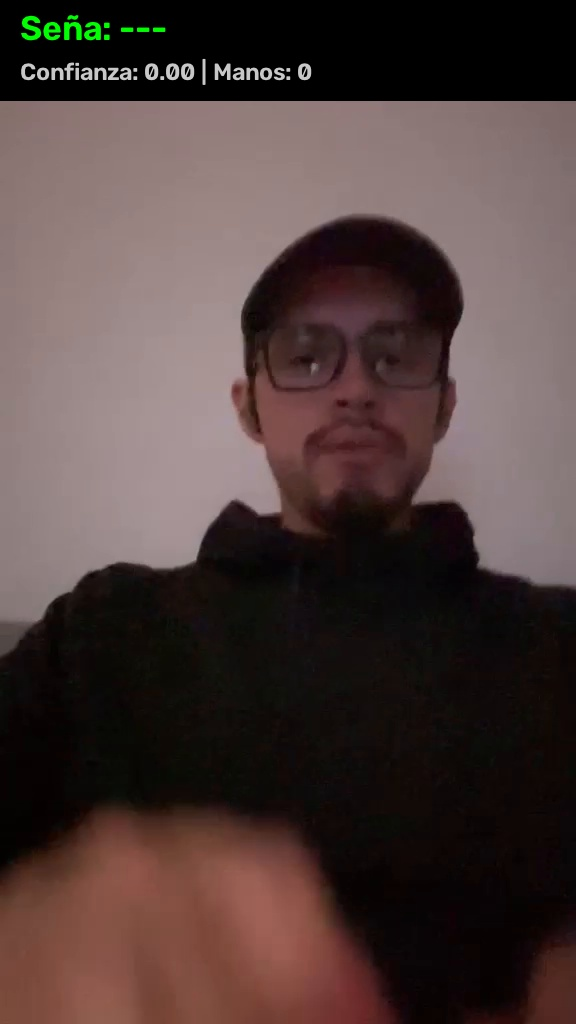

Video guardado en: resultado_lsm.mp4
Descargando...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Detección finalizada.


In [29]:
def detectar_en_video_colab(ruta_video, ventana=7, umbral=0.60,
                            guardar_salida='resultado_lsm.mp4',
                            escalar=1.0, mostrar_preview=True, frames_preview=8):
    """Procesa un video en Colab, guarda el resultado y ofrece descarga."""
    det = DetectorLSM(ventana=ventana, umbral_confianza=umbral)
    cap = cv2.VideoCapture(ruta_video)
    if not cap.isOpened():
        raise RuntimeError(f'No se pudo abrir el video: {ruta_video}')

    ancho = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH) * escalar)
    alto = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT) * escalar)
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0

    cuatrocc = cv2.VideoWriter_fourcc(*'mp4v')
    escritor = cv2.VideoWriter(guardar_salida, cuatrocc, fps, (ancho, alto))

    preview_frames = []
    frame_idx = 0

    print('Procesando video...')

    while True:
        ret, frame = cap.read()
        if not ret:
            break
        frame_idx += 1
        if escalar != 1.0:
            frame = cv2.resize(frame, (ancho, alto))

        frame, etiqueta, conf, num_manos = det.predecir_frame(frame)

        cv2.rectangle(frame, (0, 0), (ancho, 100), (0, 0, 0), -1)
        cv2.putText(frame, f'Seña: {etiqueta}', (20, 40),
                    cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 255, 0), 3)
        cv2.putText(frame, f'Confianza: {conf:.2f} | Manos: {num_manos}', (20, 80),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (200, 200, 200), 2)

        escritor.write(frame)

        if mostrar_preview and len(preview_frames) < frames_preview:
            _, buf = cv2.imencode('.jpg', frame)
            preview_frames.append(buf.tobytes())

    cap.release()
    escritor.release()

    if mostrar_preview and preview_frames:
        print(f'Vista previa de {len(preview_frames)} frames procesados:')
        for img_bytes in preview_frames:
            display(Image(data=img_bytes, format='jpeg'))

    print(f'Video guardado en: {guardar_salida}')
    print('Descargando...')
    files.download(guardar_salida)
    print('Detección finalizada.')

# Ejemplo en Colab:
subido = files.upload()  # sube tu video, ej: 'entrada.mp4'
detectar_en_video_colab('entrada.mp4', ventana=7, umbral=0.60)


## 8. Cómo usar en Google Colab (paso a paso)

### Paso A: Subir el notebook
1. Sube `lsm_deteccion_video_colab.ipynb` a Google Colab.
2. Conecta un runtime (Conectar → Cambiar tipo de runtime → Python 3).

### Paso B: Instalar dependencias
Ejecuta la celda de instalación con `!pip install ...`.

### Paso C: Subir tus videos y el modelo
Usa el botón archivos de la barra izquierda o ejecuta:
```python
from google.colab import files
subido = files.upload()  # selecciona tu video .mp4
```
Si la descarga automática del modelo falla, sube también `hand_landmarker.task`.

### Paso D: Recolectar datos
1. Ejecuta `capturar_datos_video_colab(...)` para cada seña.
2. Cada frame se guarda como una línea en el CSV con estructura EDA.
3. Repite con al menos 300-600 frames por clase.
4. Ejecuta `unir_datos()` para crear `landmarks_lsm.csv`.

### Paso E: Entrenar y evaluar
1. Ejecuta las celdas de preprocesamiento, entrenamiento y evaluación.
2. El modelo se guarda como `modelo_lsm.pkl`, `scaler_lsm.pkl`, `encoder_lsm.pkl` y `columnas_lsm.pkl`.

### Paso F: Detectar y descargar resultado
1. Sube un video de prueba con `files.upload()`.
2. Ejecuta `detectar_en_video_colab('video.mp4')`.
3. Se descargará automáticamente `resultado_lsm.mp4` con las detecciones.


## 9. Recomendaciones

- **Datos:** mínimo 300-600 frames por clase, con variedad de personas y ángulos.
- **Modelo Tasks:** se descarga automáticamente `hand_landmarker.task` (requiere internet). Si falla, súbelo manualmente.
- **LSM:** valida con personas sordas o intérpretes certificados. No asumas que es igual al ASL.
- **En Colab:** los archivos se borran al cerrar la sesión; descarga los `.pkl` y `.csv` importantes.
- **Ética:** esta herramienta no reemplaza a un intérprete de LSM. No grabes a personas sin consentimiento.
